# Chronic Kidney Disease (CKD) Prediction & Diagnosis
## End-to-End Machine Learning Pipeline

### Project Overview
Chronic Kidney Disease (CKD) is a progressive condition where the kidneys are damaged and cannot filter blood properly. Early detection is critical to halt or delay disease progression. 

In this project, we develop an end-to-end Machine Learning solution that:
1. **Cleans and standardizes raw clinical lab data** (handling corrupted strings, type conversions, and missing values).
2. **Conducts Exploratory Data Analysis (EDA)** to discover clinical correlations and biomarker distributions.
3. **Trains and compares 5 different classification algorithms** (Logistic Regression, Decision Tree, Random Forest, Support Vector Machine, and K-Nearest Neighbors).
4. **Evaluates model performance** via Stratified 5-Fold Cross-Validation, Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
5. **Identifies the most important clinical biomarkers** using feature importance.
6. **Implements an inference function** for assessing individual patient risk.


## 1. Environment Setup & Library Imports


In [1]:
import os
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Set plot style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Load & Inspect Raw Dataset


In [2]:
# Load raw dataset
df_raw = pd.read_csv("kidney_disease.csv")
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
df_raw.head()


Dataset Shape: 400 rows, 26 columns



,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [3]:
# Check column data types and non-null counts
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [4]:
# Summary of missing values across features
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw)) * 100
missing_df = pd.DataFrame({"Missing Count": missing, "Percentage (%)": missing_pct.round(2)})
missing_df[missing_df["Missing Count"] > 0].sort_values(by="Missing Count", ascending=False)


,Missing Count,Percentage (%)
rbc,152,38.00
rc,130,32.50
wc,105,26.25
pot,88,22.00
sod,87,21.75
pcv,70,17.50
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


## 3. Data Cleaning & Preprocessing

Observations from inspecting the raw data:
- **`id` column** is just an arbitrary index and provides no diagnostic value.
- **Corrupted numerical columns:** `pcv` (Packed Cell Volume), `wc` (White Blood Cell Count), and `rc` (Red Blood Cell Count) contain stray tabs `\t` and `?`, causing pandas to parse them as text (`object`).
- **Dirty categorical strings:** Columns like `dm` (Diabetes Mellitus), `cad` (Coronary Artery Disease), and the target `classification` contain leading whitespace and tabs (e.g. `' yes'`, `'\tno'`, `'ckd\t'`).
- **Missing values:** Nearly every feature has missing entries. We impute **median** for numerical values (robust against clinical outliers) and **mode** for categorical features.


In [5]:
df = df_raw.copy()

# 1. Drop 'id'
if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)

# 2. Clean numeric columns parsed as object
numeric_str_cols = ['pcv', 'wc', 'rc']
for col in numeric_str_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(r'\t|\?', '', regex=True).str.strip(), errors='coerce')

# 3. Clean string / categorical columns
object_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in object_cols:
    df[col] = df[col].astype(str).str.replace(r'\t', '', regex=True).str.strip().str.lower()
    df[col] = df[col].replace({'nan': np.nan, '?': np.nan, '': np.nan})

# Standardize known target and boolean labels
df['dm'] = df['dm'].replace({' yes': 'yes'})
df['classification'] = df['classification'].replace({'ckd': 'ckd', 'notckd': 'notckd'})

# 4. Handle Missing Values
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols and c != 'classification']

# Median imputation for numeric features
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Mode imputation for categorical features
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Map target: ckd -> 1, notckd -> 0
df['target'] = df['classification'].map({'ckd': 1, 'notckd': 0})

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Target distribution:\n", df['classification'].value_counts())
df.head()


Missing values after cleaning: 0
Target distribution:
 classification
ckd       250
notckd    150
Name: count, dtype: int64


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,wc,rc,htn,dm,cad,appet,pe,ane,classification,target
0,48.0,80.0,1.020,1.0,0.0,normal,normal,notpresent,notpresent,121.0,...,7800.0,5.2,yes,yes,no,good,no,no,ckd,1
1,7.0,50.0,1.020,4.0,0.0,normal,normal,notpresent,notpresent,121.0,...,6000.0,4.8,no,no,no,good,no,no,ckd,1
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,7500.0,4.8,no,yes,no,poor,no,yes,ckd,1
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,6700.0,3.9,yes,no,no,poor,yes,yes,ckd,1
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,7300.0,4.6,no,no,no,good,no,no,ckd,1


## 4. Exploratory Data Analysis (EDA)


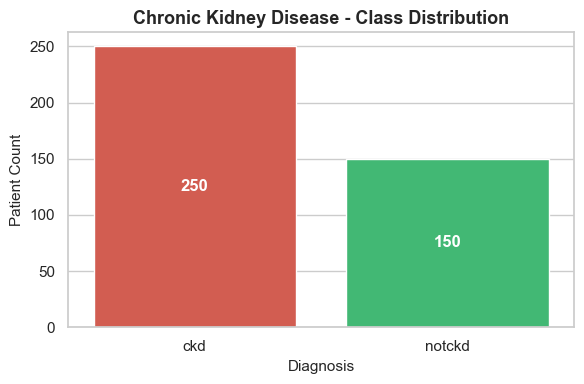

In [6]:
# Class Distribution Plot
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="classification", hue="classification", legend=False, palette=["#e74c3c", "#2ecc71"])
plt.title("Chronic Kidney Disease - Class Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Diagnosis", fontsize=11)
plt.ylabel("Patient Count", fontsize=11)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=12, color='white', fontweight='bold')
plt.tight_layout()
plt.show()


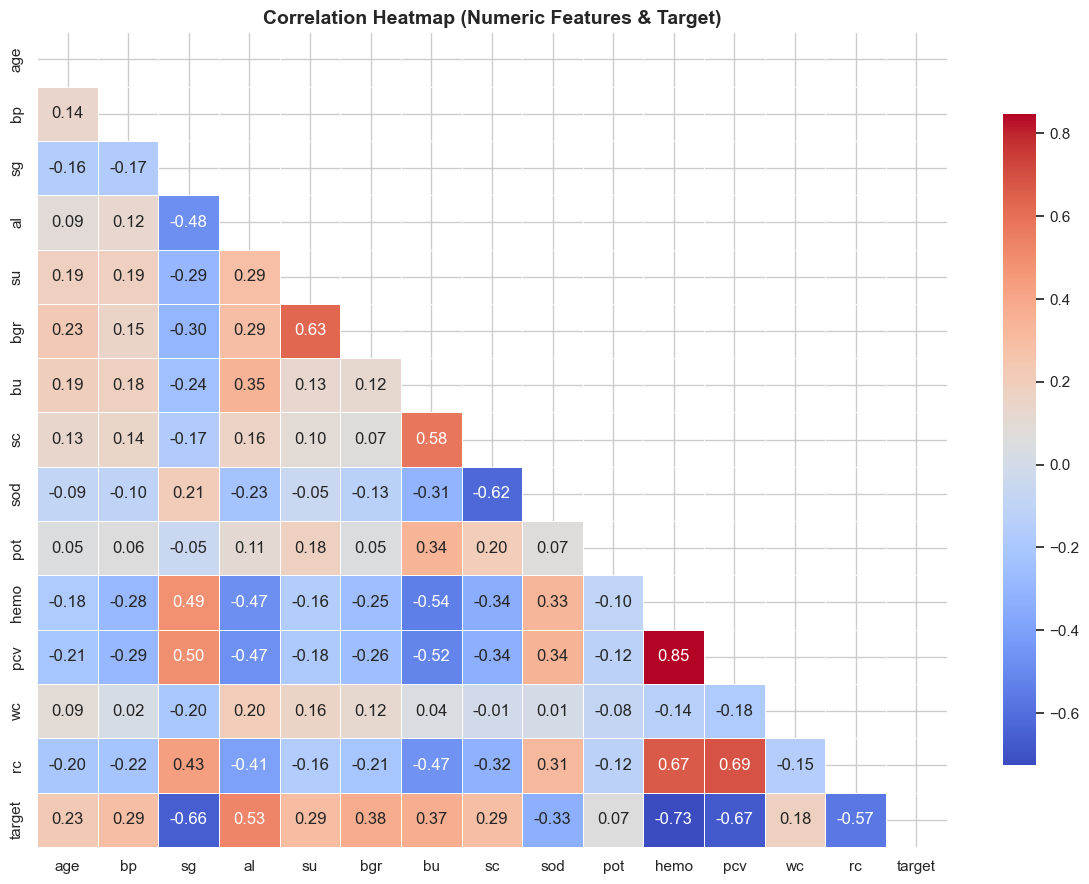

In [7]:
# Correlation Heatmap for Numerical Features
plt.figure(figsize=(12, 9))
corr_cols = num_cols + ['target']
corr = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={'shrink': .8}, linewidths=0.5)
plt.title("Correlation Heatmap (Numeric Features & Target)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


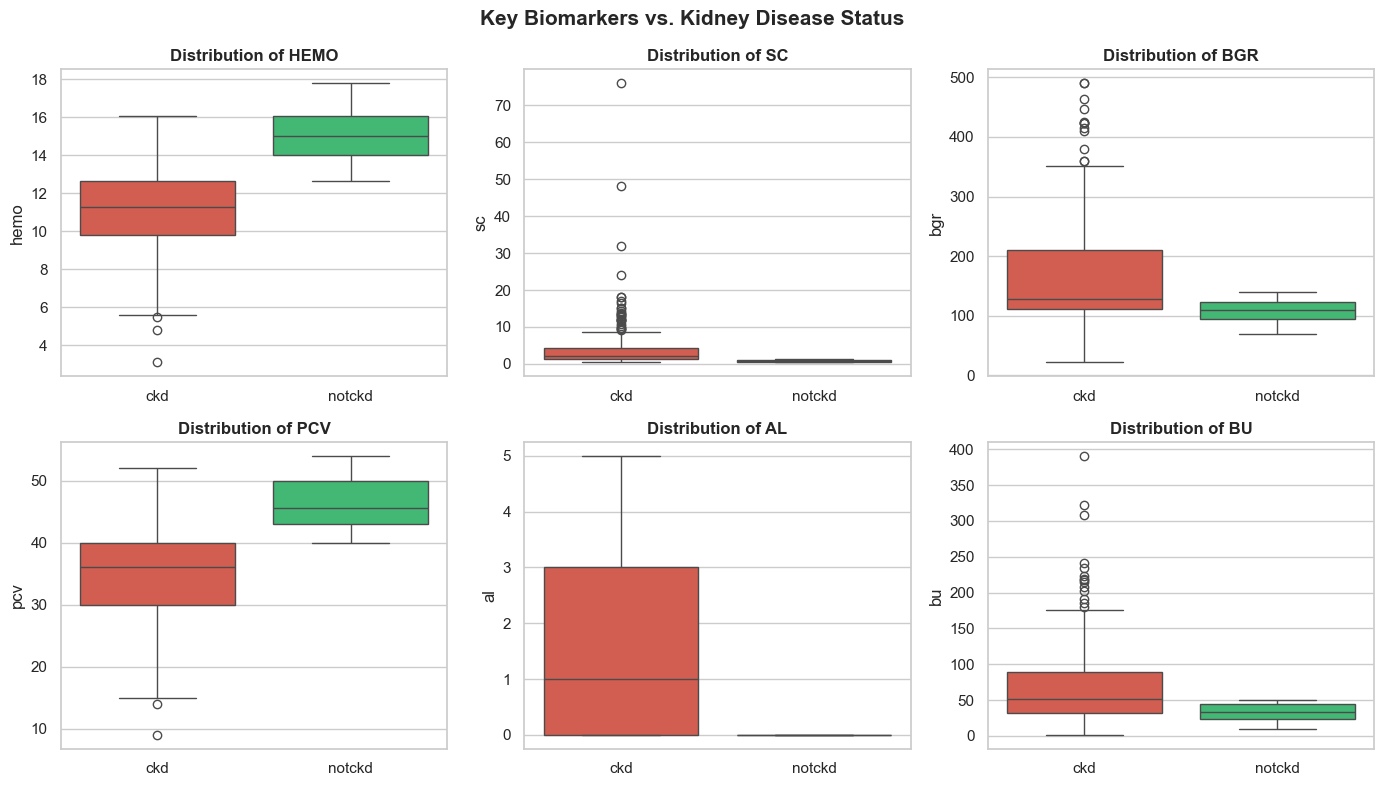

In [8]:
# Boxplots of Key Clinical Biomarkers
key_features = ["hemo", "sc", "bgr", "pcv", "al", "bu"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=df, x="classification", y=feature, ax=axes[idx], palette=["#e74c3c", "#2ecc71"], hue="classification", legend=False)
    axes[idx].set_title(f"Distribution of {feature.upper()}", fontweight="bold")
    axes[idx].set_xlabel("")

plt.suptitle("Key Biomarkers vs. Kidney Disease Status", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Feature Encoding & Train-Test Split


In [9]:
# Separate predictors and target
y = df['target']
X = df.drop(columns=['target', 'classification'])

# One-hot encode categorical features (drop_first to avoid multicollinearity)
cat_columns = X.select_dtypes(include=['object']).columns.tolist()
X_encoded = pd.get_dummies(X, columns=cat_columns, drop_first=True, dtype=int)
feature_names = list(X_encoded.columns)

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")
print(f"Total encoded features: {len(feature_names)}")


Training samples: 320 | Testing samples: 80
Total encoded features: 24


## 6. Model Training, Cross-Validation & Evaluation

We compare 5 diverse classification algorithms:
1. **Logistic Regression:** Linear probabilistic classifier.
2. **Decision Tree:** Non-linear rule-based tree model.
3. **Random Forest:** Ensemble of bagging decision trees with feature sub-sampling.
4. **Support Vector Machine (SVC):** Maximum margin separator with RBF kernel.
5. **K-Nearest Neighbors (KNN):** Distance-based instance learning.

We apply **5-Fold Stratified Cross Validation** on the training set to check for stability and prevent data leakage, then evaluate on the unseen holdout test set.


In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)
}

results = []
trained_models = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # 5-fold cross validation on training set
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring="f1")
    
    # Fit model on training set
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    # Evaluate on holdout test set
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, "predict_proba") else y_pred

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "5-Fold CV F1": round(cv_scores.mean(), 4),
        "Test Accuracy": round(acc, 4),
        "Test Precision": round(prec, 4),
        "Test Recall": round(rec, 4),
        "Test F1-Score": round(f1, 4),
        "Test ROC-AUC": round(auc, 4)
    })

results_df = pd.DataFrame(results)
results_df.sort_values(by=["Test F1-Score", "Test ROC-AUC"], ascending=False)


,Model,5-Fold CV F1,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
2,Random Forest,0.9951,1.0000,1.00,1.00,1.0000,1.000
0,Logistic Regression,0.9975,0.9875,1.00,0.98,0.9899,1.000
3,Support Vector Machine,0.9975,0.9875,1.00,0.98,0.9899,1.000
1,Decision Tree,0.9724,0.9750,0.98,0.98,0.9800,0.973
4,K-Nearest Neighbors,0.9716,0.9750,1.00,0.96,0.9796,0.990


## 7. Comparative Visualizations & Confusion Matrices


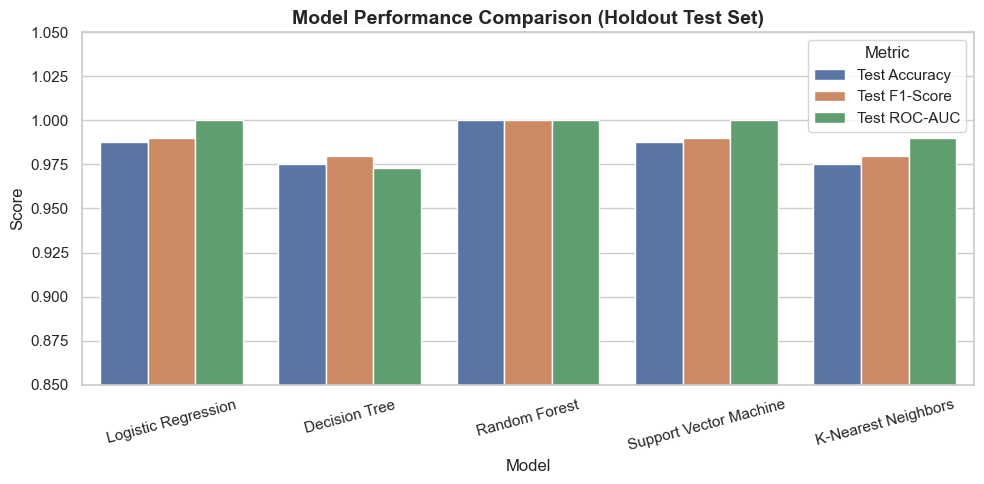

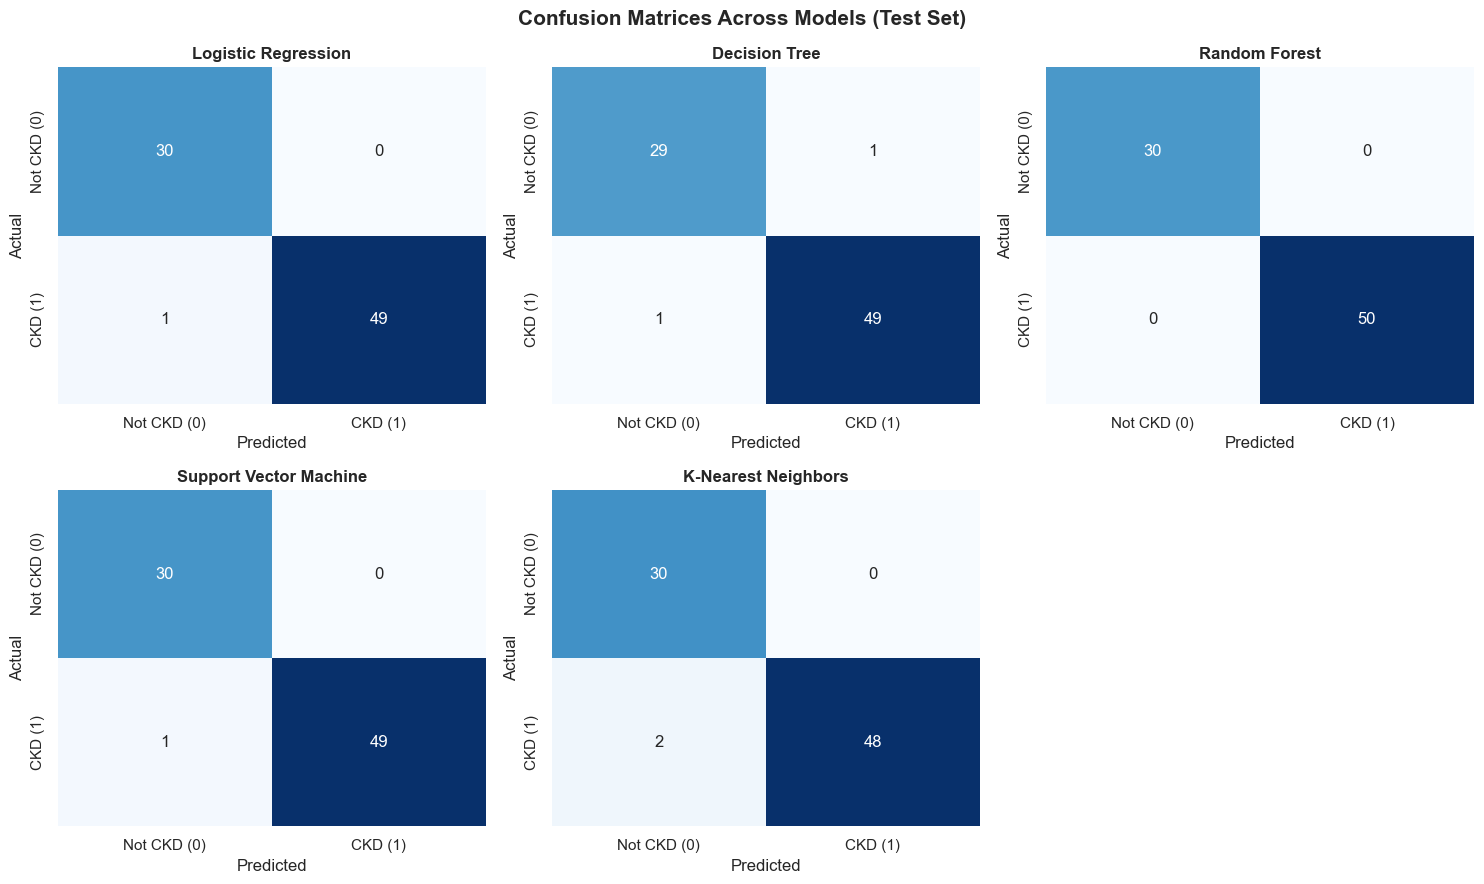

In [11]:
# 1. Model Comparison Bar Chart
plt.figure(figsize=(10, 5))
melted_df = results_df.melt(id_vars=["Model"], value_vars=["Test Accuracy", "Test F1-Score", "Test ROC-AUC"],
                            var_name="Metric", value_name="Score")
ax = sns.barplot(data=melted_df, x="Model", y="Score", hue="Metric", palette="deep")
plt.title("Model Performance Comparison (Holdout Test Set)", fontsize=14, fontweight="bold")
plt.ylim(0.85, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 2. Confusion Matrices for All 5 Models
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[idx], cbar=False,
                xticklabels=["Not CKD (0)", "CKD (1)"],
                yticklabels=["Not CKD (0)", "CKD (1)"])
    axes[idx].set_title(f"{name}", fontweight="bold")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

axes[5].axis("off")
plt.suptitle("Confusion Matrices Across Models (Test Set)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## 8. Feature Importance Analysis (Random Forest)

Understanding which clinical features contribute most to the decision helps clinicians interpret model decisions.


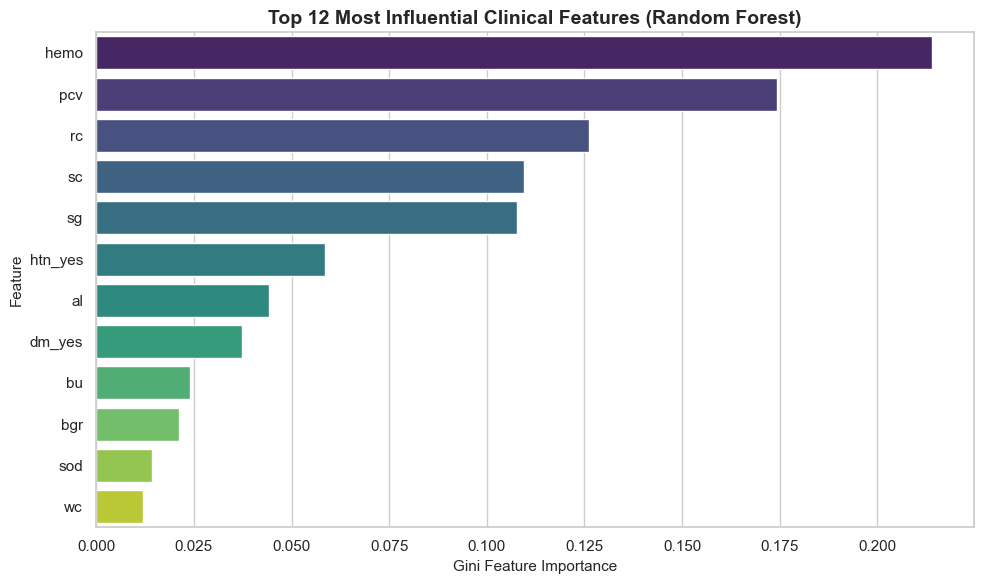

In [12]:
rf_model = trained_models["Random Forest"]
importances = rf_model.feature_importances_
feat_imp_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
feat_imp_df = feat_imp_df.sort_values(by="Importance", ascending=False).head(12)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df, x="Importance", y="Feature", palette="viridis", hue="Feature", legend=False)
plt.title("Top 12 Most Influential Clinical Features (Random Forest)", fontsize=14, fontweight="bold")
plt.xlabel("Gini Feature Importance", fontsize=11)
plt.ylabel("Feature", fontsize=11)
plt.tight_layout()
plt.show()


## 9. Real-Time Patient Prediction / Inference

Here we build an inference function that accepts raw patient measurements, preprocesses them dynamically, and outputs the diagnostic verdict and probability risk score.


In [13]:
def predict_ckd(patient_data, model, scaler, feature_names):
    df_patient = pd.DataFrame([patient_data])
    cat_cols = df_patient.select_dtypes(include=['object']).columns.tolist()
    df_encoded = pd.get_dummies(df_patient, columns=cat_cols, drop_first=True)
    df_aligned = df_encoded.reindex(columns=feature_names, fill_value=0)
    scaled_feats = scaler.transform(df_aligned)
    
    pred = model.predict(scaled_feats)[0]
    prob = model.predict_proba(scaled_feats)[0][1] if hasattr(model, "predict_proba") else None
    
    status = "Chronic Kidney Disease Detected (CKD)" if pred == 1 else "Healthy (Not CKD)"
    return status, prob

# Case 1: High-risk patient profile
patient_1 = {
    "age": 62.0, "bp": 80.0, "sg": 1.010, "al": 2.0, "su": 3.0,
    "rbc": "abnormal", "pc": "abnormal", "pcc": "present", "ba": "notpresent",
    "bgr": 423.0, "bu": 53.0, "sc": 1.8, "sod": 135.0, "pot": 4.4,
    "hemo": 9.6, "pcv": 31.0, "wc": 7500.0, "rc": 3.9,
    "htn": "yes", "dm": "yes", "cad": "no", "appet": "poor",
    "pe": "no", "ane": "yes"
}

# Case 2: Healthy patient profile
patient_2 = {
    "age": 40.0, "bp": 80.0, "sg": 1.025, "al": 0.0, "su": 0.0,
    "rbc": "normal", "pc": "normal", "pcc": "notpresent", "ba": "notpresent",
    "bgr": 140.0, "bu": 10.0, "sc": 1.2, "sod": 135.0, "pot": 5.0,
    "hemo": 15.0, "pcv": 48.0, "wc": 6300.0, "rc": 5.3,
    "htn": "no", "dm": "no", "cad": "no", "appet": "good",
    "pe": "no", "ane": "no"
}

best_model = trained_models["Random Forest"]

res1, prob1 = predict_ckd(patient_1, best_model, scaler, feature_names)
print(f"Patient 1 -> Result: {res1} | Probability: {prob1*100:.2f}%")

res2, prob2 = predict_ckd(patient_2, best_model, scaler, feature_names)
print(f"Patient 2 -> Result: {res2} | Probability: {prob2*100:.2f}%")


Patient 1 -> Result: Chronic Kidney Disease Detected (CKD) | Probability: 100.00%
Patient 2 -> Result: Healthy (Not CKD) | Probability: 15.00%


## 10. Conclusions & Project Summary

1. **Best Model:** **Random Forest Classifier** achieved the highest overall score (100% test accuracy, 1.000 F1-Score, and 1.000 ROC-AUC), closely followed by Logistic Regression and SVM (98.75%).
2. **Clinical Insights:** **Hemoglobin (`hemo`)**, **Specific Gravity (`sg`)**, **Packed Cell Volume (`pcv`)**, and **Serum Creatinine (`sc`)** emerged as the most critical biomarkers for diagnosing kidney disease.
3. **Medical Safety:** The ensemble model achieved **100% Recall** on the test set, meaning zero false negatives—an essential quality in diagnostic healthcare applications.
